# Survey và EDA AIT-LDS v2.1

Tám archive no-pcaps, lần chạy `ait-v21-01`. Notebook đọc bảng do bộ kiểm kê sinh trực tiếp từ archive. Mỗi bảng chỉ công bố số tổng hợp. Các biểu đồ thời gian dùng cửa sổ riêng của từng testbed, gồm biên đầu và loại biên cuối.

## 0. Môi trường và phạm vi chạy

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"configs/archives.csv").exists())
run = root/"outputs/runs/ait-v21-01"
figures = run/"figures"
figures.mkdir(exist_ok=True)
tot = pd.read_csv(run/"totals.csv").set_index("dataset").sort_index()
def read_all(name):
    return pd.concat([pd.read_csv(run/ds/(name+".csv")) for ds in tot.index], ignore_index=True)
def show_plot(ax, filename, ylabel):
    ax.set_ylabel(ylabel)
    ax.figure.tight_layout()
    target = figures/(filename+".png")
    ax.figure.savefig(target, dpi=140)
    plt.close(ax.figure)
    display(Image(filename=str(target)))
files = read_all("files")
labels = read_all("labels")
windows = read_all("label_windows")
extra = read_all("extended_quality")
hours = pd.concat([read_all("hours"),read_all("extended_hours")],ignore_index=True)
accounts = pd.DataFrame({ds:json.loads((run/ds/"account.json").read_text()) | json.loads((run/ds/"history.json").read_text()) for ds in tot.index}).T
assert len(tot)==8

## 1. Câu hỏi và đơn vị

Có thể nối một hoạt động xác thực với tài khoản và sắp theo thời gian đến đâu? Đơn vị kiểm kê là dòng vật lý. Đơn vị hành vi là tài khoản được nêu trong trường `acct` trên cùng host và testbed. Một thao tác có thể sinh nhiều dòng.

In [2]:
display(tot[['files','hosts','text_files','binary','lines']])

,files,hosts,text_files,binary,lines
dataset,,,,,
fox,676,30,510,166,33216199
harrison,587,27,460,127,33552846
russellmitchell,503,22,410,93,26263657
santos,513,30,403,110,25529176
shaw,991,26,538,453,36979746
wardbeck,690,30,486,204,31538566
wheeler,708,36,526,182,33705629
wilson,815,36,527,288,40617166


## 2. Lượng log theo dataset

Mẫu số là toàn bộ dòng trong file được phân loại văn bản ở mỗi dataset, cả trong và ngoài mô phỏng.

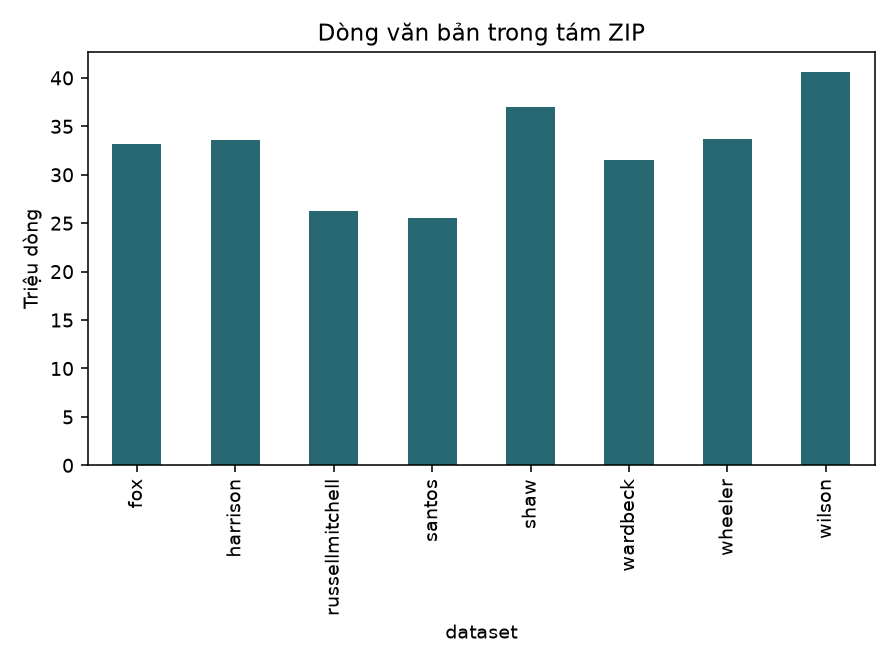

wilson có nhiều dòng nhất (40,617,166).


In [3]:
show_plot(tot.lines.div(1e6).plot.bar(title="Dòng văn bản trong tám ZIP",color="#286873"),"volume","Triệu dòng")
print(f"{tot.lines.idxmax()} có nhiều dòng nhất ({tot.lines.max():,}).")

## 3. Schema và nguồn

`files.csv` giữ dataset, host, đường dẫn gốc, số byte, số dòng và trạng thái parser. Luôn ghép đường dẫn đầy đủ, kể cả phần tên rotation.

In [4]:
source_totals=files.groupby("source").lines.sum().sort_values(ascending=False)
display(source_totals.head(8).astype(int))
print(f"Nguồn {source_totals.index[0]} chiếm {source_totals.iloc[0]/tot.lines.sum():.1%} tổng dòng văn bản.")

source
suricata                       217031623
logstash                        24604071
ait.aecid.attacker.wpdiscuz      6231290
dnsmasq.log                      5557391
apache2                          3528936
sm.log                           1221412
horde                             907745
syslog                            513982
Name: lines, dtype: int64

Nguồn suricata chiếm 83.0% tổng dòng văn bản.


## 4. Thực thể và liên kết

Khóa tài khoản có phạm vi dataset và host. Tài khoản audit có thể là đối tượng xác thực hoặc tài khoản dịch vụ. Các số dưới đây đo độ phủ của chuỗi `acct` trong phần audit có thời gian hợp lệ.

In [5]:
display(accounts[['accounts','host_account_pairs','pairs_with_history']])

,accounts,host_account_pairs,pairs_with_history
fox,12,20,20
harrison,11,17,17
russellmitchell,8,15,15
santos,13,20,20
shaw,13,20,20
wardbeck,17,26,26
wheeler,16,22,22
wilson,18,26,26


## 5. Dữ liệu thiếu

Mẫu số là các dòng audit trong cửa sổ mô phỏng. Tỷ lệ có acct đo khả năng liên kết cho nhóm log này.

In [6]:
audit = read_all("hours").query("source=='audit'").groupby("dataset").lines.sum()
display(pd.DataFrame(dict(audit_lines=audit,with_acct=accounts.with_account,coverage=accounts.with_account/audit)))

,audit_lines,with_acct,coverage
fox,24082,19081,0.792335
harrison,25358,20446,0.806294
russellmitchell,18740,14689,0.783831
santos,24042,20102,0.836120
shaw,31332,25468,0.812843
wardbeck,29455,24526,0.832660
wheeler,31143,26162,0.840060
wilson,38512,32498,0.843841


## 6. Hợp lệ và trùng

Kiểm tra trùng khóa file và lặp tham chiếu dòng trong annotation. Những dòng có cùng nội dung ở các thời điểm khác nhau vẫn được giữ. Độ trùng nội dung toàn corpus chưa đo.

In [7]:
assert not files.duplicated(["dataset","path"]).any()
display(tot[['repeated_ref','malformed','out_of_bounds','unresolved_file']])

,repeated_ref,malformed,out_of_bounds,unresolved_file
dataset,,,,
fox,0,0,0,0
harrison,0,0,0,0
russellmitchell,0,0,0,0
santos,0,0,0,0
shaw,0,0,0,0
wardbeck,0,0,0,0
wheeler,0,0,0,0
wilson,0,0,0,0


## 7. Toàn vẹn thời gian

Audit dùng epoch. Auth dùng lịch testbed cho năm thiếu và cấu hình UTC của host. JSON dùng offset nguồn. Các dòng bộ đếm Suricata kế thừa giờ của tiêu đề khối. Báo riêng nguồn chưa có parser.

In [8]:
quality=tot[['timed_lines','inside','outside','unknown']].rename(columns={'timed_lines':'lines'}).add(extra.groupby('dataset')[['lines','inside','outside','unknown']].sum(),fill_value=0).astype(int)
quality['unprofiled']=tot.lines-quality.lines
assert (quality.lines==quality.inside+quality.outside+quality.unknown).all()
quality.to_csv(run/'time_quality.csv')
display(quality)

,lines,inside,outside,unknown,unprofiled
dataset,,,,,
fox,29323438,25209012,3728659,385767,3892761
harrison,28855039,24487975,3973517,393547,4697807
russellmitchell,23168187,19504557,3349337,314293,3095470
santos,22487205,19328410,2851856,306939,3041971
shaw,32182480,28212601,3521097,448782,4797266
wardbeck,27222363,23429467,3412902,379994,4316203
wheeler,27532704,23711203,3441266,380235,6172925
wilson,34420173,30165058,3799095,456020,6196993


## 8. Độ bao phủ

Đếm host có log và host có ít nhất một dòng định giờ được trong mô phỏng. Khoảng trống có thể do phạm vi nguồn hoặc bộ đọc.

In [9]:
display(pd.DataFrame(dict(in_inventory=tot.hosts,with_timed_data=hours.groupby('dataset').host.nunique())))

,in_inventory,with_timed_data
dataset,,
fox,30,13
harrison,27,11
russellmitchell,22,11
santos,30,11
shaw,26,12
wardbeck,30,12
wheeler,36,13
wilson,36,11


## 9. Phân bố theo nguồn

Đếm mọi dòng văn bản ở mọi thời điểm lưu trong từng archive. Phần ngoài tám nguồn lớn nhất vẫn nằm trong tổng kiểm kê.

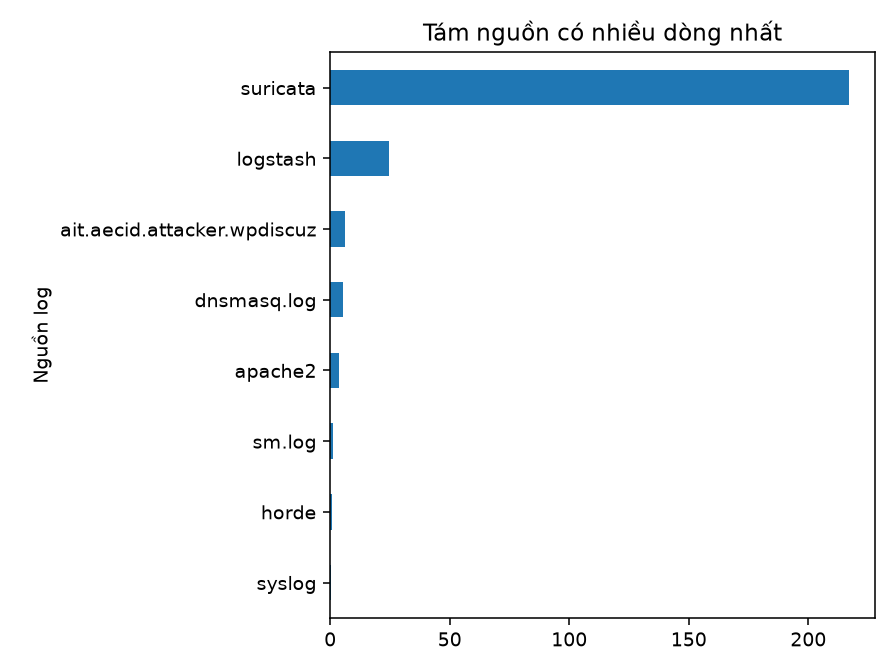

In [10]:
show_plot(source_totals.head(8).sort_values().div(1e6).plot.barh(title="Tám nguồn có nhiều dòng nhất"),"sources","Nguồn log")

## 10. Hồ sơ host và tài khoản

Tổng số dòng theo host phụ thuộc dịch vụ và cấu hình log. Phân vị tính trên toàn bộ host có file thuộc phạm vi.

In [11]:
by_host=files.groupby(['dataset','host']).lines.sum()
display(by_host.groupby(level=0).quantile([.5,.9,1]).unstack().astype(int))
display(accounts[['host_account_pairs','audit_with_account','tied_pairs']])

,0.5,0.9,1.0
dataset,,,
fox,14079,3932011,4631170
harrison,13901,4041724,4739916
russellmitchell,22325,3174976,3826979
santos,9603,3085405,3791497
shaw,16675,4609703,5432352
wardbeck,15668,3872264,4610944
wheeler,14638,3975249,4810071
wilson,13934,4852048,5674362


,host_account_pairs,audit_with_account,tied_pairs
fox,20,19081,6950
harrison,17,20446,6459
russellmitchell,15,14689,5050
santos,20,20102,7695
shaw,20,25468,9563
wardbeck,26,24526,9073
wheeler,22,26162,10181
wilson,26,32498,11932


## 11. Hoạt động theo giờ

So sánh từng dataset theo số giờ từ đầu mô phỏng. Đường biểu diễn bao gồm năm nhóm nguồn được định giờ. Giá trị thiếu để trống.

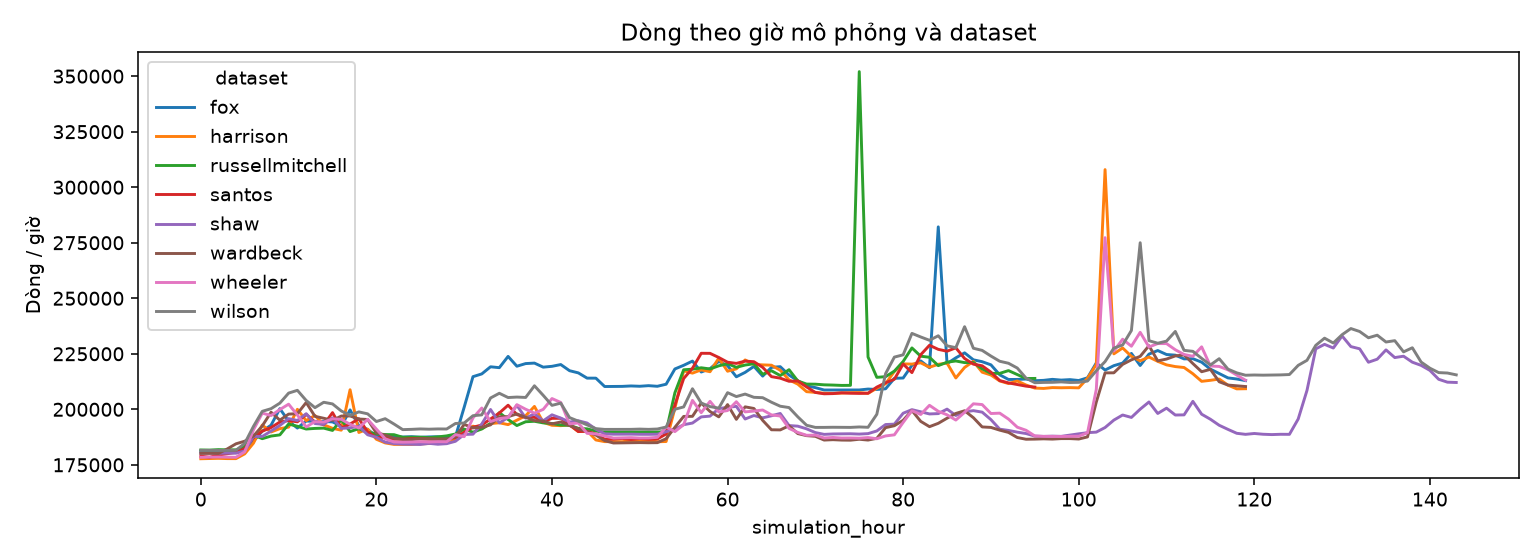

Tổng 194,048,283 dòng trong cửa sổ, trên 225,191,589 dòng của năm nhóm đã xét.


In [12]:
metadata=json.loads((root/'outputs/archive_manifest.json').read_text())
starts={r['dataset']:pd.Timestamp(r['metadata']['start'],tz='UTC').timestamp() for r in metadata}
hours['simulation_hour']=((hours.hour_epoch-hours.dataset.map(starts))/3600).astype(int)
timeline=hours.pivot_table(index='simulation_hour',columns='dataset',values='lines',aggfunc='sum')
assert hours.lines.sum()==quality.inside.sum()
show_plot(timeline.plot(figsize=(11,4),title='Dòng theo giờ mô phỏng và dataset'),"timeline","Dòng / giờ")
print(f"Tổng {int(timeline.sum().sum()):,} dòng trong cửa sổ, trên {int(quality.lines.sum()):,} dòng của năm nhóm đã xét.")

## 12. Phiên và chuỗi

Nhóm theo dataset–host–acct–ses khi mã phiên khác sentinel. Dùng số dòng trong nhóm để mô tả bằng chứng phiên. Trình tự audit liền kề chỉ lấy cặp có timestamp tăng, thứ tự trong các cụm trùng giờ vẫn mơ hồ.

In [13]:
display(accounts[['with_account','with_session','session_groups']])
transitions=read_all('sequences').groupby(['previous','following']).pairs.sum().sort_values(ascending=False)
display(transitions.head(8))

,with_account,with_session,session_groups
fox,19081,7170,2393
harrison,20446,7120,2374
russellmitchell,14689,5733,1914
santos,20102,5718,1908
shaw,25468,8549,2851
wardbeck,24526,7185,2400
wheeler,26162,7122,2375
wilson,32498,8631,2882


previous    following 
USER_ACCT   USER_AUTH     43518
USER_END    USER_ACCT     18862
USER_START  CRED_DISP     18202
CRED_ACQ    USER_START    12333
USER_AUTH   USER_ACCT     11343
USER_ACCT   CRED_ACQ       7880
CRED_DISP   USER_END       3085
USER_AUTH   USER_AUTH       320
Name: pairs, dtype: int64

## 13. Hành vi nền và tính mới

Với từng cặp host–acct, so loại sự kiện với toàn bộ lịch sử có timestamp nhỏ hơn trong cùng mô phỏng. Loại nhóm thời điểm đầu tiên khỏi mẫu số.

In [14]:
display(accounts[['novel','eligible']].assign(rate=accounts.novel/accounts.eligible))

,novel,eligible,rate
fox,42,19045,0.002205
harrison,33,20418,0.001616
russellmitchell,36,14663,0.002455
santos,35,20066,0.001744
shaw,35,25431,0.001376
wardbeck,55,24485,0.002246
wheeler,35,26125,0.001340
wilson,44,32453,0.001356


## 14. Quan hệ đa nguồn

Bảng đếm số cặp dataset–host có nguồn tương ứng trong cửa sổ. Cùng host chỉ chứng minh hai nguồn cùng quan sát host, chưa xác định hai dòng thuộc cùng phiên.

In [15]:
pairs=hours.pivot_table(index=['dataset','host'],columns='source',values='lines',aggfunc='sum',fill_value=0).gt(0).astype(int)
display(pairs.T @ pairs)

source,audit,auth,eve,logstash,stats
source,,,,,
audit,56,56,56,0,56
auth,56,86,56,0,56
eve,56,56,56,0,56
logstash,0,0,0,8,0
stats,56,56,56,0,56


## 15. Nhãn và khoảng tấn công

Mẫu số ghép là toàn bộ annotation. Mẫu số phân tích trước–trong–sau là các dòng trong file đích có nhãn hoặc file audit được profile. Bảng giữ riêng dòng có annotation và dòng còn lại.

,annotation_rows,matched,unique_lines,assignments,multilabel_rows
dataset,,,,,
fox,456884,456884,456884,1369978,456884
harrison,488171,488171,488171,1463868,488171
russellmitchell,61862,61862,61862,184517,61862
santos,47367,47367,47367,141150,47367
shaw,5876,5876,5876,17034,5876
wardbeck,51525,51525,51525,153656,51525
wheeler,491082,491082,491082,1472635,491082
wilson,494125,494125,494125,1481414,494125


annotated                    0       1
dataset         phase                 
fox             after    68460       0
                before  159026   44018
                during    4345  412866
harrison        after    49308     398
                before  244649   69335
                during   10183  418438
russellmitchell after    55279    5708
                before  191748   46346
                during    2046    9808
santos          after    40331       0
                before  224360   38563
                during    4969    8804
shaw            after   102346      17
                before  268140       2
                during    4046    5857
wardbeck        after    30705       0
                before  270409   45257
                during    2766    6268
wheeler         after    10097       0
                before  314581   57556
                during   59426  433526
wilson          after   124651       0
                before  370072   63691
                during    3672  430434

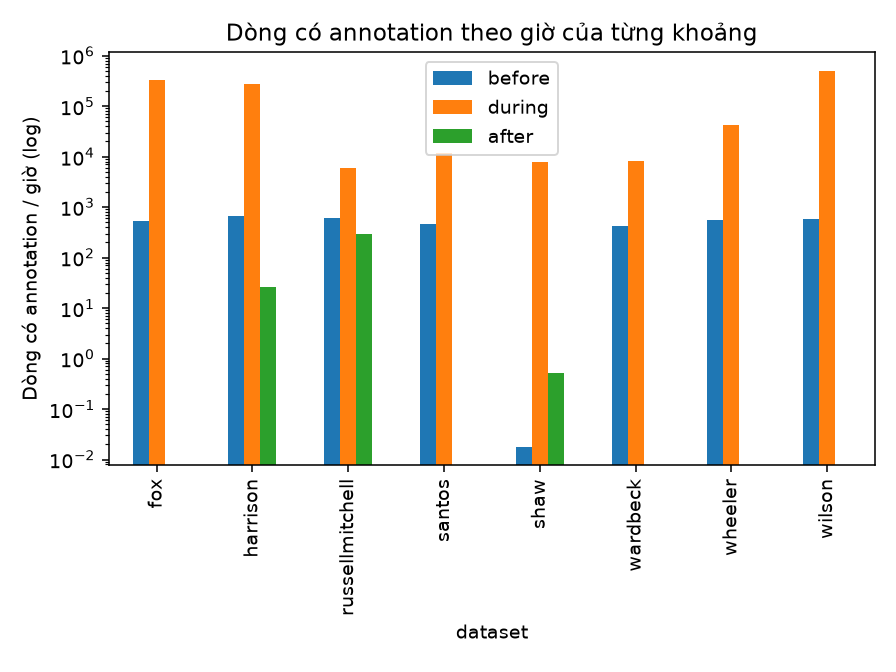

Năm nhãn có nhiều lượt gán nhất:


label
foothold         1723266
attacker_http    1717345
dirb             1689485
attacker          372920
dnsteal           372920
Name: assignments, dtype: int64

In [16]:
display(tot[['annotation_rows','matched','unique_lines','assignments','multilabel_rows']])
phase=windows.pivot_table(index=['dataset','phase'],columns='annotated',values='lines',aggfunc='sum',fill_value=0)
display(phase)
assert windows.loc[windows.annotated==1,'lines'].sum()==tot.matched.sum()
phase.to_csv(run/'label_phase_summary.csv')
dur=pd.read_csv(root/'configs/published_windows.csv').set_index('dataset').apply(pd.to_datetime)
seconds=pd.DataFrame({'before':(dur.attack_start-dur.simulation_start).dt.total_seconds(),'during':(dur.attack_end-dur.attack_start).dt.total_seconds(),'after':(dur.simulation_end-dur.attack_end).dt.total_seconds()})
rate=phase[1].unstack().reindex(columns=seconds.columns).fillna(0).div(seconds)*3600
show_plot(rate.plot.bar(logy=True,title='Dòng có annotation theo giờ của từng khoảng'),"attack_windows","Dòng có annotation / giờ (log)")
print("Năm nhãn có nhiều lượt gán nhất:")
display(labels.groupby('label').assignments.sum().nlargest(5))

## 16. Tín hiệu hành vi ứng viên

Khả thi trên phần có trường tương ứng gồm tần suất loại sự kiện trước thời điểm hiện tại, số host từng thấy trong cùng testbed và độ dài lịch sử. Để diễn giải được cần ghi rõ vai trò acct, mức thiếu và các tài khoản dịch vụ.

In [17]:
display(accounts[['with_account','with_session','eligible']].sum().to_frame('dòng'))

,dòng
with_account,182972
with_session,57228
eligible,182686


## 17. Leakage và dữ liệu Test

Nhãn, rule, lịch tấn công và đường dẫn file kịch bản chỉ phục vụ đối chiếu. Với câu hỏi về tính mới, mọi dòng cùng timestamp dùng cùng lịch sử quá khứ. Một phép chia tương lai phải kiểm tra trùng thực thể và kịch bản giữa các phần. Phạm vi hiện tại dừng ở kiểm tra dữ liệu.

In [18]:
display(pd.DataFrame([('Nhãn và rule','sau sự kiện','đối chiếu hồi cứu'),('Tên testbed / file kịch bản','metadata','kiểm tra tương quan giả'),('acct, loại audit, timestamp','khi ghi log','kiểm tra trường hợp thiếu'),('Toàn bộ lịch sử và dữ liệu Test','có quan sát tương lai','loại khỏi đặc trưng tại sự kiện')],columns=['Trường','Khả dụng','Cách sử dụng']))

,Trường,Khả dụng,Cách sử dụng
0,Nhãn và rule,sau sự kiện,đối chiếu hồi cứu
1,Tên testbed / file kịch bản,metadata,kiểm tra tương quan giả
2,"acct, loại audit, timestamp",khi ghi log,kiểm tra trường hợp thiếu
3,Toàn bộ lịch sử và dữ liệu Test,có quan sát tương lai,loại khỏi đặc trưng tại sự kiện


## 18. Kết luận và Data Quality Log

Có thể nghiên cứu chuỗi xác thực trên những host có audit. Diễn giải việc chiếm tài khoản thực cần thêm danh tính, xác nhận sự cố và lịch sử dài hơn. Mỗi dòng dưới đây ghi phạm vi bị ảnh hưởng và quyết định xử lý.

In [19]:
dq=pd.DataFrame([('File nhị phân',int(tot.binary.sum()),'file','kiểm kê byte, bỏ phép đếm dòng'),('Chưa áp dụng parser thời gian',int(quality.unprofiled.sum()),'dòng','giữ trong tổng kiểm kê'),('Ngoài cửa sổ',int(quality.outside.sum()),'dòng','loại khỏi timeline'),('Không xác định giờ trên nguồn đã xét',int(quality.unknown.sum()),'dòng','ghi riêng'),('Trùng thời điểm trong chuỗi audit',int(accounts.tied_pairs.sum()),'cặp liền kề','bỏ cặp có thời điểm bằng nhau'),('Tham chiếu nhãn ngoài biên',int(tot.out_of_bounds.sum()),'annotation','ghi số lỗi ghép')],columns=['Vấn đề','Số lượng','Đơn vị','Quyết định'])
dq.to_csv(run/'quality_log.csv',index=False)
display(dq)
print(f"{int(tot.matched.sum()):,} dòng riêng có annotation. Ranh giới sự cố độc lập chưa được xác định.")

,Vấn đề,Số lượng,Đơn vị,Quyết định
0,File nhị phân,1623,file,"kiểm kê byte, bỏ phép đếm dòng"
1,Chưa áp dụng parser thời gian,36211396,dòng,giữ trong tổng kiểm kê
2,Ngoài cửa sổ,28077729,dòng,loại khỏi timeline
3,Không xác định giờ trên nguồn đã xét,3065577,dòng,ghi riêng
4,Trùng thời điểm trong chuỗi audit,66903,cặp liền kề,bỏ cặp có thời điểm bằng nhau
5,Tham chiếu nhãn ngoài biên,0,annotation,ghi số lỗi ghép


2,096,892 dòng riêng có annotation. Ranh giới sự cố độc lập chưa được xác định.
